# 4. Deeper checks: how sure are we, and would it hold up?

Notebooks 2 and 3 found that a 5-row table (shipping option, plus before or after noon for Same Day) predicts lateness
about as well as the tuned LightGBM model. This notebook asks whether that conclusion is solid, and whether the system
would survive outside this one test period.

| question | method |
|---|---|
| 1. Is the model really no better than the table, or is the gap just noise? | bootstrap confidence interval on the AUC difference, resampling whole orders |
| 2. Does the answer depend on where we cut the timeline? | rolling-origin (expanding window) validation |
| 3. Does acting on the model beat acting on the table, at the thresholds that matter? | decision curve analysis (net benefit) |
| 4. Is it equally good for every shipping option, market and region? | within-option AUC, calibration error by group |
| 5. Would the inputs and scores stay stable after deployment? | population stability index (PSI) and a retraining rule |

Run notebooks 2 and 3 first (this notebook loads `models/models.joblib`). The functions live in `core.py` (section 10) and
are covered by tests.

In [1]:
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
import core
from core import DATE, FEATURES, MODE, TARGET
pd.set_option("display.width", 160)

models = joblib.load(core.MODELS_FILE)
late, params = models["late"], models["late_params"]
data = core.shipped_only(core.load_dataco())
train, val, test = core.time_split(data)                     # the same split as notebooks 2 and 3

lookup = train.assign(key=core.rule_key(train)).groupby("key")[TARGET].mean()
p_table = pd.Series(core.rule_key(test)).map(lookup).to_numpy()          # the 5-row table
p_raw = late.predict_proba(test[FEATURES])[:, 1]                         # LightGBM score
calib = core.fit_calibrator(late.predict_proba(val[FEATURES])[:, 1], val[TARGET])   # fitted on validation only
p_model = calib.predict(p_raw)                                           # LightGBM as a probability
y = test[TARGET].to_numpy()
print(len(test), "test orders |", "ROC-AUC  LightGBM:", round(roc_auc_score(y, p_raw), 4), " table:", round(roc_auc_score(y, p_table), 4))

25915 test orders | ROC-AUC  LightGBM: 0.7786  table: 0.7766


d:\annaconda\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\annaconda\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "d:\annaconda\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "d:\annaconda\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "d:\annaconda\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^

## 1. Is the gap between the model and the table real?

One test period gives one AUC for each. To see how much that number could move by chance, the test orders are resampled
500 times (a whole order at a time, because the items of one order share their outcome) and both AUCs are recomputed on the
*same* resample. The spread of the **difference** is what matters:

- If its 95% interval includes 0, the model is not distinguishably better than the table.
- If it excludes 0 but is tiny, the difference is real but too small to change any decision. Judge by size, not by the interval alone.

In [2]:
groups = test["Order Id"] if "Order Id" in test.columns else None
res = core.cluster_bootstrap_auc(y, {"LightGBM": p_raw, "5-row table": p_table}, groups, n_boot=500)
rows = [{"score": k, "ROC-AUC": v["auc"], "95% low": v["lo"], "95% high": v["hi"]} for k, v in res.items() if k != "difference"]
d = res["difference"]; rows.append({"score": d["label"], "ROC-AUC": d["auc"], "95% low": d["lo"], "95% high": d["hi"]})
pd.DataFrame(rows).round(4)

,score,ROC-AUC,95% low,95% high
0,LightGBM,0.7786,0.7696,0.7877
1,5-row table,0.7766,0.7695,0.7844
2,LightGBM minus 5-row table,0.0020,-0.0028,0.0066


## 2. Does it depend on where the timeline is cut?

The main test uses one split. Here the model and the table are refitted five times on an expanding window: train on
everything before a block of time, test on that block. The first 40% of the timeline is only ever used for training. Model
settings are the ones tuned in notebook 2, held fixed.

,fold,trained on,test from,test to,test orders,LightGBM,5-row table,difference
0,1,69106,2016-02-26,2016-07-02,20731,0.7750,0.7776,-0.0026
1,2,89837,2016-07-02,2016-11-05,20732,0.7739,0.7764,-0.0025
2,3,110569,2016-11-05,2017-03-11,20732,0.7677,0.7718,-0.0040
3,4,131301,2017-03-11,2017-07-16,20732,0.7775,0.7698,0.0077
4,5,152033,2017-07-16,2018-01-31,20732,0.7811,0.7780,0.0030


mean difference +0.0003, standard deviation 0.0050; LightGBM ahead in 2 of 5 folds


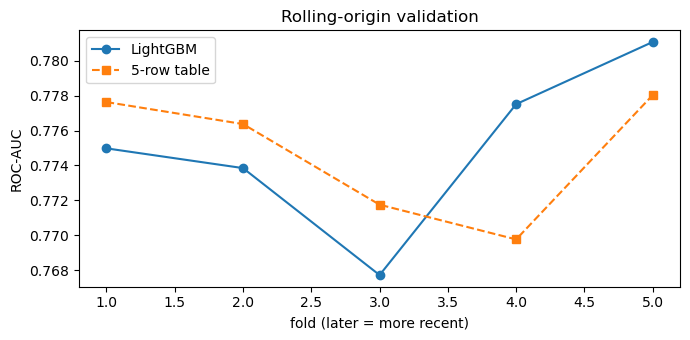

In [3]:
rows = []
for k, (tr, te) in enumerate(core.rolling_origin_folds(data, n_folds=5, first_train=0.4), 1):
    m = Pipeline([("prep", core.make_preprocessor()), ("clf", LGBMClassifier(**params, **core.LATE_FIXED))]).fit(tr[FEATURES], tr[TARGET])
    lk = tr.assign(key=core.rule_key(tr)).groupby("key")[TARGET].mean()
    pt = pd.Series(core.rule_key(te)).map(lk).fillna(tr[TARGET].mean()).to_numpy()
    a_m, a_t = roc_auc_score(te[TARGET], m.predict_proba(te[FEATURES])[:, 1]), roc_auc_score(te[TARGET], pt)
    rows.append({"fold": k, "trained on": len(tr), "test from": te[DATE].min().date(), "test to": te[DATE].max().date(),
                 "test orders": len(te), "LightGBM": a_m, "5-row table": a_t, "difference": a_m - a_t})
roll = pd.DataFrame(rows)
display(roll.round(4))
print(f"mean difference {roll['difference'].mean():+.4f}, standard deviation {roll['difference'].std():.4f}; "
      f"LightGBM ahead in {(roll['difference'] > 0).sum()} of {len(roll)} folds")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(roll["fold"], roll["LightGBM"], "o-", label="LightGBM"); ax.plot(roll["fold"], roll["5-row table"], "s--", label="5-row table")
ax.set(xlabel="fold (later = more recent)", ylabel="ROC-AUC", title="Rolling-origin validation"); ax.legend(); plt.tight_layout(); plt.show()

## 3. Does acting on the model beat acting on the table?

ROC-AUC says how well orders are ranked, not whether acting on the ranking is worth it. **Net benefit** answers that
(Vickers and Elkin, 2006). Flag every order with a score of at least *t*; each true catch earns 1 and each false alarm costs
*t / (1 - t)*, which is the cost of a false alarm relative to the cost of a missed late order at that threshold. A threshold of 0.17 means a missed
late order is worth about 5 false alarms (the assumption in the app). The line that is highest at your threshold is the better policy.
"Act on all" flags everything; "act on none" is 0.

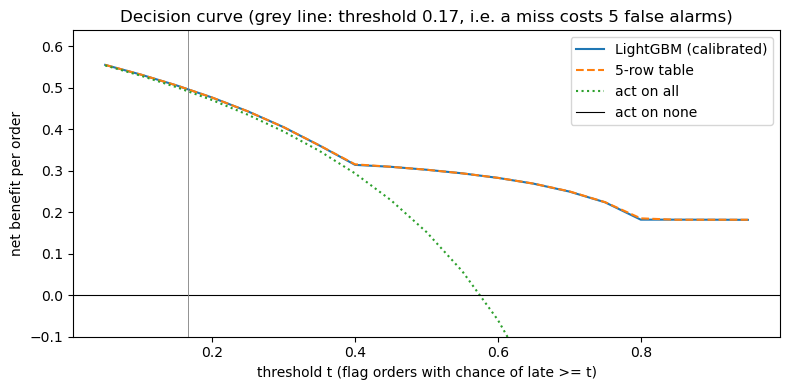

,threshold,act on all,LightGBM (calibrated),5-row table
1,0.1,0.5290,0.5317,0.5317
3,0.2,0.4701,0.4762,0.4763
5,0.3,0.3944,0.4049,0.4050
9,0.5,0.1522,0.3024,0.3024
13,0.7,-0.4130,0.2498,0.2503
17,0.9,-3.2389,0.1820,0.1819


In [4]:
dc = core.decision_curve(y, {"LightGBM (calibrated)": p_model, "5-row table": p_table})
fig, ax = plt.subplots(figsize=(8, 4))
for col, style in [("LightGBM (calibrated)", "-"), ("5-row table", "--"), ("act on all", ":")]:
    ax.plot(dc["threshold"], dc[col], style, label=col)
ax.axhline(0, color="k", lw=.8, label="act on none"); ax.axvline(1 / 6, color="grey", lw=.6)
ax.set(xlabel="threshold t (flag orders with chance of late >= t)", ylabel="net benefit per order", ylim=(-0.1, dc[["LightGBM (calibrated)", "5-row table"]].max().max() * 1.15),
       title="Decision curve (grey line: threshold 0.17, i.e. a miss costs 5 false alarms)")
ax.legend(); plt.tight_layout(); plt.show()
dc[dc["threshold"].isin([0.1, 0.2, 0.3, 0.5, 0.7, 0.9])].round(4)

## 4. Is it equally good for every group?

**4a. Within one shipping option.** Almost all of the model's ROC-AUC comes from telling shipping options apart, which the
table does too. The sharper test is *inside* an option, where the table gives every order the same score (AUC 0.5, apart from
Same Day, where it splits at noon). If the model finds anything beyond the promise, its within-option AUC rises above 0.5.

In [5]:
d = test.assign(p_raw=p_raw, p_table=p_table)
rows = []
for mode, g in d.groupby(MODE):
    if g[TARGET].nunique() < 2:
        rows.append({"shipping mode": mode, "orders": len(g), "late rate": g[TARGET].mean(), "LightGBM AUC inside the option": np.nan,
                     "table AUC inside the option": np.nan}); continue
    rows.append({"shipping mode": mode, "orders": len(g), "late rate": g[TARGET].mean(),
                 "LightGBM AUC inside the option": roc_auc_score(g[TARGET], g["p_raw"]),
                 "table AUC inside the option": roc_auc_score(g[TARGET], g["p_table"])})
pd.DataFrame(rows).round(3)

,shipping mode,orders,late rate,LightGBM AUC inside the option,table AUC inside the option
0,First Class,3904,1.000,NaN,NaN
1,Same Day,1445,0.561,1.000,1.0
2,Second Class,5147,0.803,0.505,0.5
3,Standard Class,15419,0.394,0.505,0.5


(An empty AUC means every order in that option has the same outcome, so there is nothing to rank. First Class is always late.)

**4b. By market and region.** For each group with enough test orders (1,000 for markets, 300 for regions): its late rate, the model's average predicted
chance, the calibration error (average gap between predicted and observed late rate), and both AUCs.

In [6]:
def by_group(col, min_n=1000):
    d = test.assign(p=p_model, t=p_table, r=p_raw)
    rows = []
    for k, g in d.groupby(col):
        if len(g) < min_n or g[TARGET].nunique() < 2: continue
        rows.append({col: k, "orders": len(g), "late rate": g[TARGET].mean(), "mean predicted": g["p"].mean(),
                     "calibration error": core.expected_calibration_error(g[TARGET], g["p"]),
                     "AUC model": roc_auc_score(g[TARGET], g["r"]), "AUC table": roc_auc_score(g[TARGET], g["t"])})
    if not rows:
        return pd.DataFrame({"note": [f"no {col} group has {min_n}+ test orders with both outcomes"]})
    return pd.DataFrame(rows).round(3).sort_values("orders", ascending=False).reset_index(drop=True)
display(by_group("Market"))
by_group("Order Region", min_n=300)

,Market,orders,late rate,mean predicted,calibration error,AUC model,AUC table
0,Europe,19943,0.575,0.577,0.012,0.781,0.779
1,Pacific Asia,5380,0.580,0.577,0.008,0.780,0.774


,Order Region,orders,late rate,mean predicted,calibration error,AUC model,AUC table
0,Western Europe,11778,0.581,0.585,0.013,0.783,0.783
1,Northern Europe,4172,0.555,0.557,0.005,0.763,0.759
2,Southern Europe,3993,0.577,0.577,0.014,0.791,0.788
3,Southeast Asia,1673,0.582,0.574,0.014,0.770,0.764
4,Oceania,1367,0.579,0.580,0.006,0.787,0.779
5,Eastern Asia,1252,0.581,0.575,0.007,0.775,0.775
6,South Asia,1088,0.576,0.581,0.021,0.786,0.784
7,South America,592,0.590,0.545,0.057,0.685,0.713


## 5. Would it stay valid after deployment?

**Drift** is when the data a model sees in use no longer looks like the data it was built on. The population stability index
(PSI) compares a column's distribution in two periods: below 0.1 is stable, 0.1 to 0.25 a moderate shift, above 0.25 a large
shift. Here it compares the training period with the test period, and the model's own scores in validation with test.

In [7]:
cols = ["Sales", "Product Price", "Order Item Quantity", "Order Item Discount Rate", "order_hour", MODE, "Market", "Department Name", "Type"]
drift = pd.DataFrame({"feature": cols, "PSI (train vs test)": [core.psi(train[c], test[c]) for c in cols]})
drift.loc[len(drift)] = ["model score (validation vs test)", core.psi(late.predict_proba(val[FEATURES])[:, 1], p_raw)]
drift["verdict"] = np.select([drift.iloc[:, 1] > 0.25, drift.iloc[:, 1] > 0.1], ["large shift", "moderate shift"], "stable")
display(drift.round(4))
q = data.groupby(data[DATE].dt.to_period("Q"))[TARGET].agg(orders="size", late_rate="mean")
q["late_rate"] = q["late_rate"].round(3)
q.T

,feature,PSI (train vs test),verdict
0,Sales,0.0701,stable
1,Product Price,0.1024,moderate shift
2,Order Item Quantity,0.1484,moderate shift
3,Order Item Discount Rate,0.0000,stable
4,order_hour,0.0006,stable
5,Shipping Mode,0.0003,stable
6,Market,3.1941,large shift
7,Department Name,1.1381,large shift
8,Type,0.0002,stable
9,model score (validation vs test),0.0570,stable


order date (DateOrders),2015Q1,2015Q2,2015Q3,2015Q4,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1
orders,14728.000,14910.000,15075.000,15241.00,14809.000,14768.000,15134.000,15215.000,14853.000,14745.000,15094.000,6156.000,2037.000
late_rate,0.571,0.569,0.583,0.57,0.575,0.585,0.564,0.576,0.568,0.563,0.578,0.571,0.587


**Reading the PSI table.** Market (3.19) and Department (1.14) show large shifts: the newest orders come almost entirely from Europe and Pacific Asia, a different mix from the training period. Yet the model score is stable (0.057) and the late rate stays between 0.56 and 0.59 in every quarter. The reason is that lateness depends on the shipping option, and the shipping-option mix is stable (0.0003). So a large input shift does **not** by itself mean the model has stopped working: input PSI gives false alarms, and the score PSI plus the observed late rate are the signals to act on.

It also means the test period represents mostly two markets, which is a limit on how far the test numbers generalise (see Threats to validity).

**A simple monitoring and retraining rule** (what would be done in operation):

1. Each month, compute the PSI of the model score and of the shipping-option mix against the training period. A PSI above 0.25 on either triggers a review.
2. Each month, compare the late rate of each shipping option with its training late rate, with a Wilson 95% interval. A rate outside its interval means the promise or the carrier process changed.
3. **Decision curve: the two policies differ by at most 0.0032 net benefit per order at any threshold from 0.05 to 0.95**, and by under 0.0005 at the six thresholds shown (for example 0.3024 against 0.3024 at t = 0.5, and 0.2498 against 0.2503 at t = 0.7). Acting on everything has negative net benefit above about t = 0.6; both policies stay positive.
4. If the company changes a promise (for example Second Class from 2 to 3 days), retrain at once: the table and the model both learned the old promise.

## 6. Threats to validity

- **Synthetic data.** Lateness here follows the promise plus random noise, so the 0.78 ROC-AUC ceiling reflects how the data was generated, not how real logistics behaves. Real orders carry carrier, weather, stock and distance effects that are not in this file.
- **One company, one period** (2015 to 2018). Nothing here shows the result transfers to other firms or years.
- **"Late" means slower than the promise,** so a company can change its late rate just by changing the promise. The model predicts a policy outcome as well as a physical one.
- **Several items per order.** Items of one order are not independent. The split is chronological and the bootstrap resamples whole orders to reduce this, but it cannot be removed completely.
- **Cancelled orders** were removed because the data labels them "not late" although nothing shipped. If they matter in the real process, they need their own treatment.
- **The test period is mostly two markets.** Europe (19,943 orders) and Pacific Asia (5,380) are the only markets with 1,000+ test orders, so the held-out numbers say little about the other markets. The rolling-origin folds, which span the whole timeline, partly cover this.
- **Small categories.** Regions and categories with few orders give unstable estimates; the app falls back to the table when the model disagrees strongly with it.
- **Costs are assumptions.** The 1 to 5 cost ratio is an illustration. Real costs of an alert and of a missed late order must come from the business.

## Findings

1. **AUC difference (LightGBM minus 5-row table): +0.0020, 95% interval -0.0028 to +0.0066.** The interval includes 0, so the model is not distinguishably better than the table (0.7786 against 0.7766 on 25,915 test orders).
2. **Rolling-origin (5 folds): mean difference +0.0003, standard deviation 0.0050; LightGBM is ahead in 2 of 5 folds** (differences from -0.0040 to +0.0077). The table wins about as often as the model, so the answer does not depend on where the timeline is cut.
3. **Decision curve: the two policies are identical to within 0.0005 net benefit at every threshold shown** (for example 0.3024 against 0.3024 at t = 0.5, and 0.2498 against 0.2503 at t = 0.7). Acting on everything has negative net benefit above about t = 0.6; both policies stay positive.
4. **Inside Second Class and Standard Class the model's AUC is 0.505 (the table's is 0.5).** Inside Same Day both reach 1.0 through the noon cut-off. Once the shipping option is known, nothing else in the data predicts lateness.
5. **Calibration is good everywhere it can be measured** (error 0.005 to 0.021, markets and regions with 1,000+ orders). The one exception is South America (592 orders): calibration error 0.057 and the model's AUC 0.685 is below the table's 0.713, i.e. the model overfits a small group. This is why the app falls back to the table when the two disagree.
6. **PSI:** large shifts in Market (3.19) and Department (1.14), moderate in Product Price (0.10) and Order Item Quantity (0.15), but the model score is stable (0.057) and the quarterly late rate stays between 0.56 and 0.59. Input drift without performance drift, because lateness depends only on the shipping option.


## 7. Save the results for the app

The app's **Evidence** page reads these tables from `models/evidence.joblib`. Run this cell last (after all the cells above).

In [ ]:
inside = []
dd = test.assign(p_raw=p_raw, p_table=p_table)
for mode, g in dd.groupby(MODE):
    ok = g[TARGET].nunique() == 2
    inside.append({"shipping mode": mode, "orders": len(g), "late rate": g[TARGET].mean(),
                   "LightGBM AUC inside the option": roc_auc_score(g[TARGET], g["p_raw"]) if ok else np.nan,
                   "table AUC inside the option": roc_auc_score(g[TARGET], g["p_table"]) if ok else np.nan})
quarterly = q.reset_index()
quarterly["quarter"] = quarterly.iloc[:, 0].astype(str)
d_ = res["difference"]
evidence = {
    "bootstrap": pd.DataFrame([{"score": k, "auc": v["auc"], "lo": v["lo"], "hi": v["hi"]} for k, v in res.items() if k != "difference"]
                              + [{"score": d_["label"], "auc": d_["auc"], "lo": d_["lo"], "hi": d_["hi"]}]),
    "rolling": roll.assign(**{"test from": roll["test from"].astype(str), "test to": roll["test to"].astype(str)}),
    "decision": dc, "within_mode": pd.DataFrame(inside), "market": by_group("Market"), "region": by_group("Order Region", min_n=300),
    "drift": drift, "quarterly": quarterly[["quarter", "orders", "late_rate"]],
}
joblib.dump(evidence, core.EVIDENCE_FILE)
print("saved", core.EVIDENCE_FILE)